# Part 1: Probability Distributions with the Expectation Maximization (EM) Algorithm

**Dataset:** Galton Families (1886): 934 adult children from 205 families, heights in inches.
**Our choice:** Fathers vs Children (the brief lets us pick mothers or fathers).
**Setup:** we pool both groups and **hide the labels**, so the data is an unlabelled mixture of two Gaussians.
EM must recover the two distributions on its own. We only reveal the labels at the end, to check what EM actually learned.

EM is implemented from scratch in [`em_gmm.py`](em_gmm.py) using NumPy only (no scikit learn, no scipy.stats).

In [1]:
# Google Colab only: fetch em_gmm.py and the dataset from the repo. Does nothing when run locally.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("em_gmm.py"):
    repo = "ml-formative-3-probability-bayes-gradient-descent"
    if not os.path.isdir(repo):
        subprocess.run(["git", "clone", "-q", f"https://github.com/igorntwari/{repo}.git"], check=True)
    os.chdir(os.path.join(repo, "part1_em_algorithm"))

In [2]:
import inspect
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import em_gmm
from em_gmm import (decision_boundary, e_step, fit_em, load_heights, mean_split_estimate,
                    posterior, score_against_labels, tracking_table)

DATA_PATH = Path("data/GaltonFamilies.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
PARENT = "father"
NAMES = ("Child", "Father")          # component 1 = shorter group, component 2 = taller group
COLORS = ("#2a9d8f", "#e76f51")
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data (and one trap to avoid)

The CSV has **one row per child**, and the father's height is repeated on every child's row.
If we took the `father` column directly, a father with 10 children would be counted 10 times.
`load_heights` keeps **one father per family**, giving 934 children + 205 fathers = 1139 heights.

In [3]:
heights, labels = load_heights(DATA_PATH, parent=PARENT)
print(f"Total heights : {heights.size}  (children: {(labels == 0).sum()}, fathers: {(labels == 1).sum()})")
print(f"Global mean   : {heights.mean():.3f} in   |  std: {heights.std():.3f} in")
print(f"Range         : {heights.min()} to {heights.max()} in")

Total heights : 1139  (children: 934, fathers: 205)
Global mean   : 67.209 in   |  std: 3.567 in
Range         : 56.0 to 79.0 in


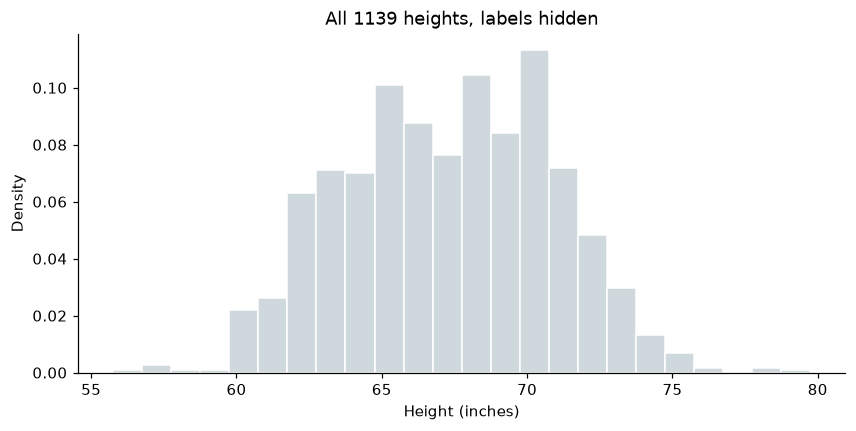

In [4]:
def inch_bins(x):
    # Galton rounded heights (mostly to the half inch), so arbitrary bin edges create fake spikes.
    return np.arange(np.floor(x.min()) - 0.25, x.max() + 1, 1.0)

def plot_histogram(ax, x, title):
    ax.hist(x, bins=inch_bins(x), density=True, color="#cfd8dc", edgecolor="white")
    ax.set(title=title, xlabel="Height (inches)", ylabel="Density")

def plot_mixture(ax, x, params, title):
    # Histogram + each weighted Gaussian + their sum. Reused for every model we compare (DRY).
    plot_histogram(ax, x, title)
    grid = np.linspace(x.min() - 3, x.max() + 3, 500)
    weighted = np.exp(np.log(params.pi) + em_gmm.gaussian_log_pdf(grid, params.mu, params.var))
    for k in range(2):
        ax.plot(grid, weighted[:, k], color=COLORS[k], lw=2,
                label=f"{NAMES[k]}: mu={params.mu[k]:.2f}, sigma={np.sqrt(params.var[k]):.2f}, pi={params.pi[k]:.2f}")
    ax.plot(grid, weighted.sum(axis=1), "k--", lw=1.5, label="Mixture (sum)")
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(9, 4))
plot_histogram(ax, heights, "All 1139 heights, labels hidden")
fig.savefig(FIG_DIR / "01_unlabelled_heights.png", bbox_inches="tight"); plt.show()

## 2. The naive idea: split at the global mean

"Draw a line at the global mean, call everything below it Children and everything above it Fathers, then average each pile."
This is exactly `mean_split_estimate`. We keep it, because it becomes **iteration 0** of EM, so the tracking table shows how much EM improves on it.

Cut at global mean = 67.209 in
  Child  pile: mean=64.2598  var=4.1428  share=0.5048
  Father pile: mean=70.2147  var=3.5711  share=0.4952


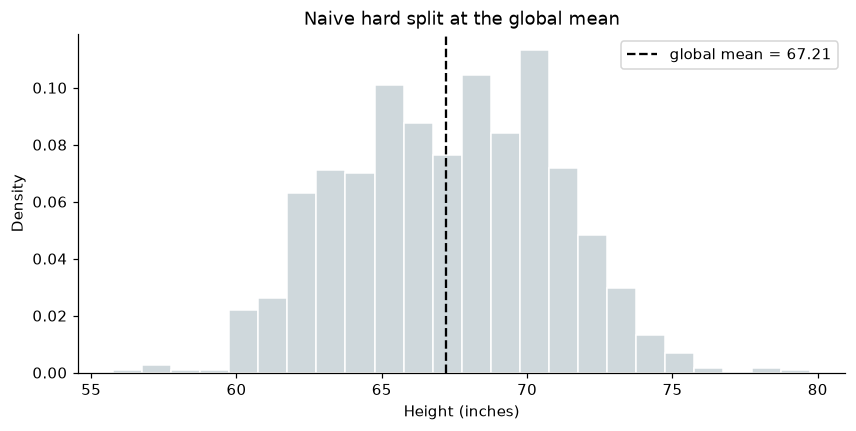

In [5]:
naive = mean_split_estimate(heights)
cut = heights.mean()
print(f"Cut at global mean = {cut:.3f} in")
for k in range(2):
    print(f"  {NAMES[k]:6s} pile: mean={naive.mu[k]:.4f}  var={naive.var[k]:.4f}  share={naive.pi[k]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
plot_histogram(ax, heights, "Naive hard split at the global mean")
ax.axvline(cut, color="k", ls="--", label=f"global mean = {cut:.2f}")
ax.legend(); fig.savefig(FIG_DIR / "02_mean_split.png", bbox_inches="tight"); plt.show()

### Why the mean split is the wrong final answer

1. **It assumes no overlap.** A 68 inch person is labelled 100% Father even though many children are 68 inches. Every point in the overlap is forced into one pile.
2. **It biases every estimate (truncation bias).** Cutting a bell curve in half removes its tail, so the short pile's mean is pulled down, the tall pile's mean is pulled up, and **both variances shrink**.
3. **The mixing weights are dictated by the cut, not the data.** It almost always produces close to a 50/50 split, whatever the true proportions are.
4. **No uncertainty.** It cannot say "70% child, 30% father". EM gives **soft assignments** (responsibilities) and a log likelihood that tells us how well the model fits.

Section 7 measures all four of these against the true labels.

## 3. The model and the mathematics of EM

Each height comes from one of two Gaussians, but we do not know which:

$$p(x) = \pi_1\,\mathcal{N}(x\mid\mu_1,\sigma_1^2) + \pi_2\,\mathcal{N}(x\mid\mu_2,\sigma_2^2), \qquad \mathcal{N}(x\mid\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-\frac{(x-\mu)^2}{2\sigma^2}}, \qquad \pi_1+\pi_2=1$$

Six parameters: two means, two variances, two mixing coefficients.

**Initialization (iteration 0):** the mean split statistics from section 2.

**E step (Expectation):** with the parameters fixed, compute each point's responsibility, Bayes' theorem applied to every height:

$$r_{ik} = P(k \mid x_i) = \frac{\pi_k\,\mathcal{N}(x_i\mid\mu_k,\sigma_k^2)}{\sum_{j=1}^{2}\pi_j\,\mathcal{N}(x_i\mid\mu_j,\sigma_j^2)}$$

**M step (Maximization):** with the responsibilities fixed, re estimate the parameters as **weighted** averages, every point contributing to both components in proportion to its responsibility:

$$N_k=\sum_i r_{ik},\qquad \mu_k=\frac{1}{N_k}\sum_i r_{ik}x_i,\qquad \sigma_k^2=\frac{1}{N_k}\sum_i r_{ik}(x_i-\mu_k)^2,\qquad \pi_k=\frac{N_k}{N}$$

**Log likelihood and stopping rule:**

$$\mathcal{L}=\sum_{i=1}^{N}\log\Big(\sum_{k=1}^{2}\pi_k\,\mathcal{N}(x_i\mid\mu_k,\sigma_k^2)\Big)$$

EM guarantees $\mathcal{L}$ never decreases. We stop when it improves by less than $10^{-6}$.

The code below is the real implementation (printed straight from `em_gmm.py`):

In [6]:
for fn in (e_step, em_gmm.m_step, fit_em):
    print(inspect.getsource(fn))

def e_step(x: np.ndarray, params: GMMParams) -> tuple[np.ndarray, float]:
    """Expectation step.

    Responsibility r[i, k] = P(component k | x_i)
                           = pi_k N(x_i | mu_k, var_k) / sum_j pi_j N(x_i | mu_j, var_j)
    Also returns the log likelihood L = sum_i log sum_k pi_k N(x_i | mu_k, var_k),
    which falls out of the same numbers (the denominator), so it costs nothing extra.
    """
    weighted_log = np.log(params.pi) + gaussian_log_pdf(x, params.mu, params.var)  # (N, K)
    log_denominator = _log_sum_exp(weighted_log)  # (N,)
    responsibilities = np.exp(weighted_log - log_denominator[:, None])
    return responsibilities, float(log_denominator.sum())

def m_step(x: np.ndarray, responsibilities: np.ndarray) -> GMMParams:
    """Maximization step: weighted maximum likelihood estimates.

    N_k    = sum_i r[i, k]                       (effective number of points in k)
    mu_k   = sum_i r[i, k] x_i / N_k
    var_k  = sum_i r[i, k] (x_i - mu_k)^2 / N_k
 

## 4. Run EM and the tracking table

In [7]:
history = fit_em(heights, init=naive)
final = history[-1].params
table = tracking_table(history, NAMES)
print(f"Converged after {history[-1].iteration} iterations "
      f"(log likelihood change < {em_gmm.DEFAULT_TOLERANCE}).\n")
print("Required tracking table (initial state + first two iterations):")
display(table.loc[[0, 1, 2]])
print("Final (converged) parameters:")
display(table.loc[[history[-1].iteration]])

Converged after 309 iterations (log likelihood change < 1e-06).

Required tracking table (initial state + first two iterations):


,mu1 (Child),mu2 (Father),sigma1^2,sigma2^2,pi1,pi2,Log Likelihood
Iteration,,,,,,,
0,64.2598,70.2147,4.1428,3.5711,0.5048,0.4952,-3071.1165
1,64.3784,70.0758,4.9168,4.2979,0.5033,0.4967,-3053.5777
2,64.4368,69.9988,5.3058,4.6724,0.5017,0.4983,-3049.7088


Final (converged) parameters:


,mu1 (Child),mu2 (Father),sigma1^2,sigma2^2,pi1,pi2,Log Likelihood
Iteration,,,,,,,
309,64.1772,69.5186,5.3024,6.0410,0.4325,0.5675,-3046.9895


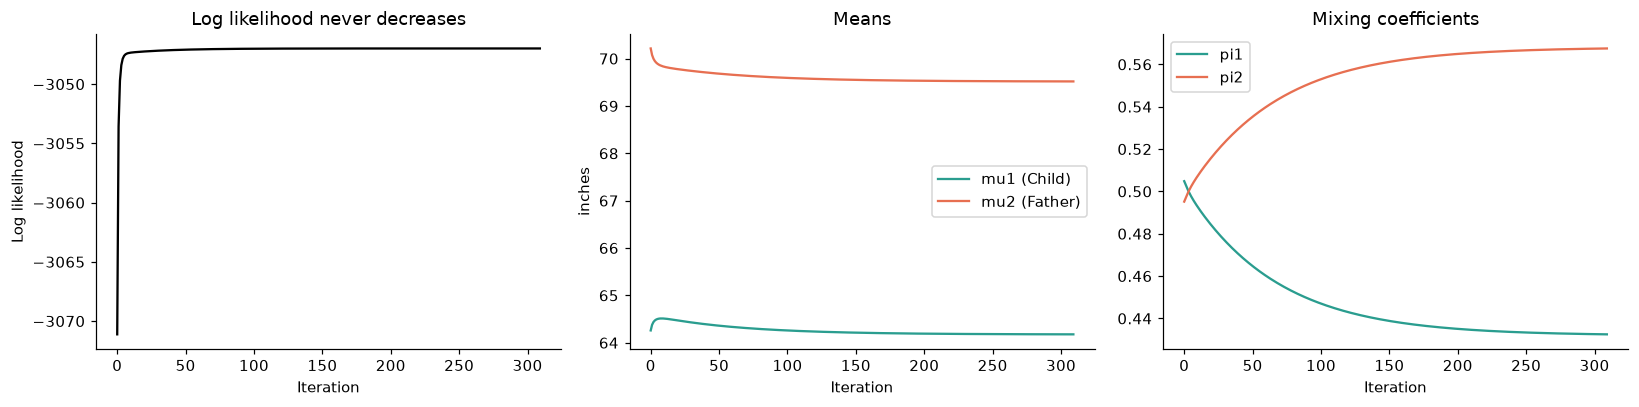

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
iters = table.index
axes[0].plot(iters, table["Log Likelihood"], color="k")
axes[0].set(title="Log likelihood never decreases", xlabel="Iteration", ylabel="Log likelihood")
for k, col in enumerate(table.columns[:2]):
    axes[1].plot(iters, table[col], color=COLORS[k], label=col)
    axes[2].plot(iters, table.iloc[:, 4 + k], color=COLORS[k], label=table.columns[4 + k])
axes[1].set(title="Means", xlabel="Iteration", ylabel="inches"); axes[1].legend()
axes[2].set(title="Mixing coefficients", xlabel="Iteration"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "03_convergence.png", bbox_inches="tight"); plt.show()

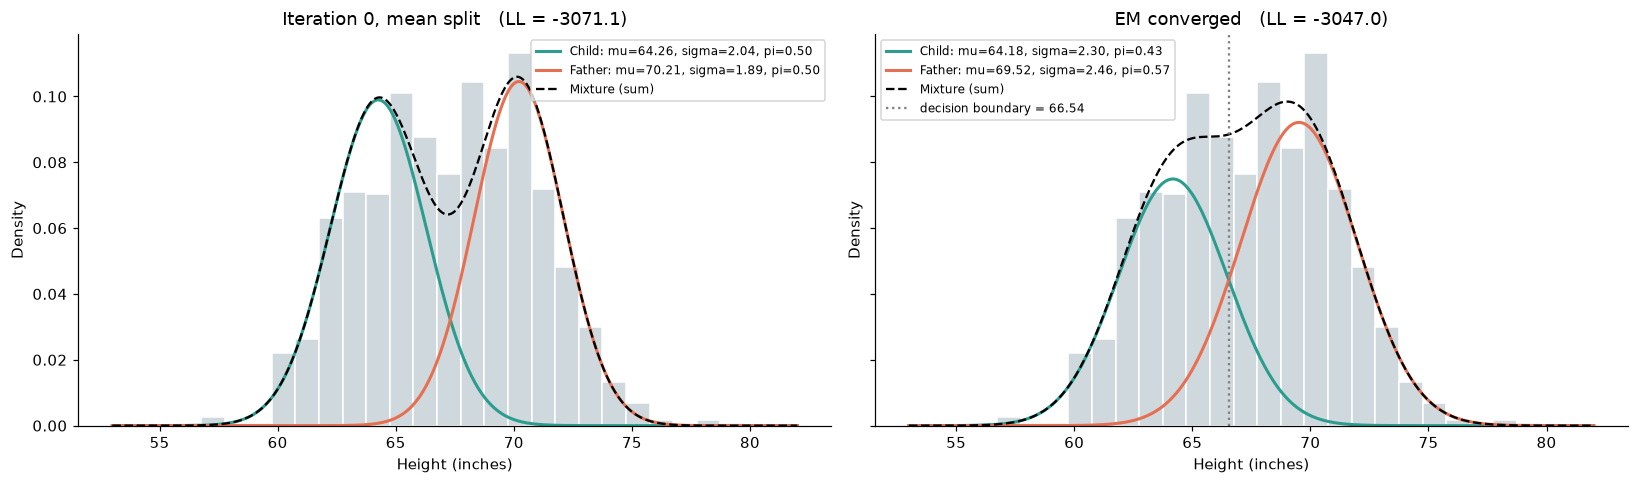

Decision boundary (P(Child) = P(Father) = 0.5): 66.54 in


In [9]:
boundary = decision_boundary(final, low=heights.min() - 10, high=heights.max() + 10)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
plot_mixture(axes[0], heights, naive, f"Iteration 0, mean split   (LL = {history[0].log_likelihood:.1f})")
plot_mixture(axes[1], heights, final, f"EM converged   (LL = {history[-1].log_likelihood:.1f})")
for b in boundary:
    axes[1].axvline(b, color="grey", ls=":", label=f"decision boundary = {b:.2f}")
axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_mean_split_vs_em.png", bbox_inches="tight"); plt.show()
print(f"Decision boundary (P(Child) = P(Father) = 0.5): {boundary[0]:.2f} in")

## 5. Live demo: classify a test height

Change `TEST_HEIGHT` (and `UNIT` to `"cm"` if the height is given in centimetres) and run the cell.
The output is the exact posterior from the E step formula with the converged parameters.

In [10]:
def classify(height, unit="in"):
    p = posterior(height, final, unit=unit)
    inches = height / em_gmm.CM_PER_INCH if unit == "cm" else height
    print(f"Test height: {height} {unit} ({inches:.2f} in)")
    print(f"  P({NAMES[0]}  | height) = {p[0]:.6f}")
    print(f"  P({NAMES[1]} | height) = {p[1]:.6f}")
    print(f"  Prediction: {NAMES[int(p.argmax())]}\n")

TEST_HEIGHT = 70.0
UNIT = "in"
classify(TEST_HEIGHT, UNIT)

Test height: 70.0 in (70.00 in)
  P(Child  | height) = 0.032786
  P(Father | height) = 0.967214
  Prediction: Father



In [11]:
for h in (60, 64, 66.5, 68, 72, 76):
    classify(h)

Test height: 60 in (60.00 in)
  P(Child  | height) = 0.996485
  P(Father | height) = 0.003515
  Prediction: Child

Test height: 64 in (64.00 in)
  P(Child  | height) = 0.909802
  P(Father | height) = 0.090198
  Prediction: Child

Test height: 66.5 in (66.50 in)
  P(Child  | height) = 0.509727
  P(Father | height) = 0.490273
  Prediction: Child

Test height: 68 in (68.00 in)
  P(Child  | height) = 0.198827
  P(Father | height) = 0.801173
  Prediction: Father

Test height: 72 in (72.00 in)
  P(Child  | height) = 0.004204
  P(Father | height) = 0.995796
  Prediction: Father

Test height: 76 in (76.00 in)
  P(Child  | height) = 0.000050
  P(Father | height) = 0.999950
  Prediction: Father



## 6. What did EM actually learn? Checking against the hidden labels

EM is unsupervised: it finds the two Gaussians that best explain the heights. Calling them "Child" and "Father" is **our** interpretation.
Because this dataset does have labels, we can test that interpretation.

EM component,Child,Father
True group,,
Daughter,392,61
Father,33,172
Son,80,401


Accuracy, Child vs Father:  EM = 0.565   mean split = 0.608   always say 'Child' = 0.820
  true Daughter: mean = 64.10 in
  true Son     : mean = 69.23 in
  true Father  : mean = 69.32 in


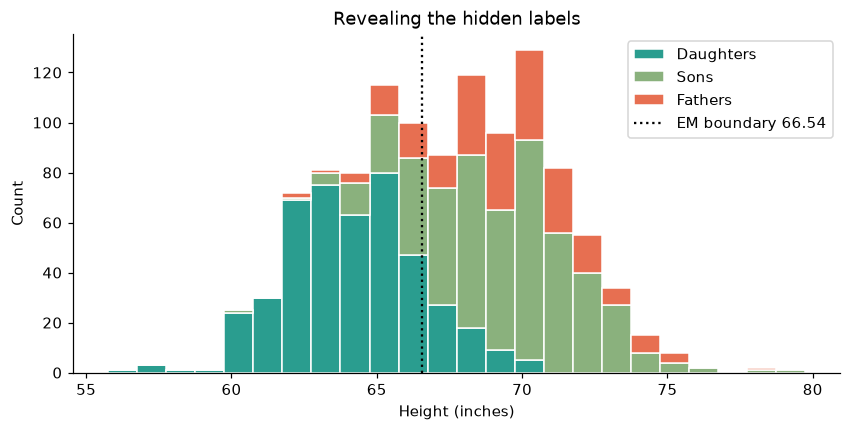

In [12]:
df = pd.read_csv(DATA_PATH, dtype={"family": str})
n_fathers = (labels == 1).sum()
true_group = np.concatenate([np.where(df["gender"] == "male", "Son", "Daughter"), np.repeat("Father", n_fathers)])

r_final, _ = e_step(heights, final)
r_naive, _ = e_step(heights, naive)
assigned = np.array(NAMES)[r_final.argmax(axis=1)]
display(pd.crosstab(pd.Series(true_group, name="True group"), pd.Series(assigned, name="EM component")))

print(f"Accuracy, Child vs Father:  EM = {score_against_labels(r_final, labels):.3f}   "
      f"mean split = {((heights > heights.mean()).astype(int) == labels).mean():.3f}   "
      f"always say 'Child' = {(labels == 0).mean():.3f}")
for grp in ("Daughter", "Son", "Father"):
    print(f"  true {grp:8s}: mean = {heights[true_group == grp].mean():.2f} in")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist([heights[true_group == g] for g in ("Daughter", "Son", "Father")], bins=inch_bins(heights), stacked=True,
        label=["Daughters", "Sons", "Fathers"], color=["#2a9d8f", "#8ab17d", "#e76f51"], edgecolor="white")
ax.axvline(boundary[0], color="k", ls=":", label=f"EM boundary {boundary[0]:.2f}")
ax.set(title="Revealing the hidden labels", xlabel="Height (inches)", ylabel="Count"); ax.legend()
fig.savefig(FIG_DIR / "05_hidden_labels.png", bbox_inches="tight"); plt.show()

**Key finding.** EM converged to means of about 64.2 and 69.5 inches. Those are the **daughters (64.1)** and the **sons and fathers together (69.2 and 69.3)**.
The "Children" in this dataset are both sons and daughters, so the children's heights are themselves bimodal, and sons are as tall as their fathers.
The strongest two Gaussian structure in the data is **sex, not generation**, and EM found exactly that.

So EM did its job correctly (it maximised the likelihood), but the label "Father" on component 2 is misleading:
most of that component is sons. As a child vs father classifier it is worse than always guessing "Child".
This is why you should never name clusters without checking them.

## 7. Controlled experiment: Fathers vs Daughters

To show the algorithm works when the two populations really are different, we repeat everything on fathers vs daughters only
(no sex confound). Here we know the true parameters, so we can score both methods.

,mu1 (Daughter),mu2 (Father),sigma1^2,sigma2^2,pi1,Accuracy
Method,,,,,,
TRUE (labels),64.1040,69.3161,5.5368,6.9734,0.6884,1.0000
Mean split,63.2246,68.8654,2.9380,5.2345,0.5562,0.8100
EM,63.7947,68.8683,4.7499,7.3492,0.6190,0.8602


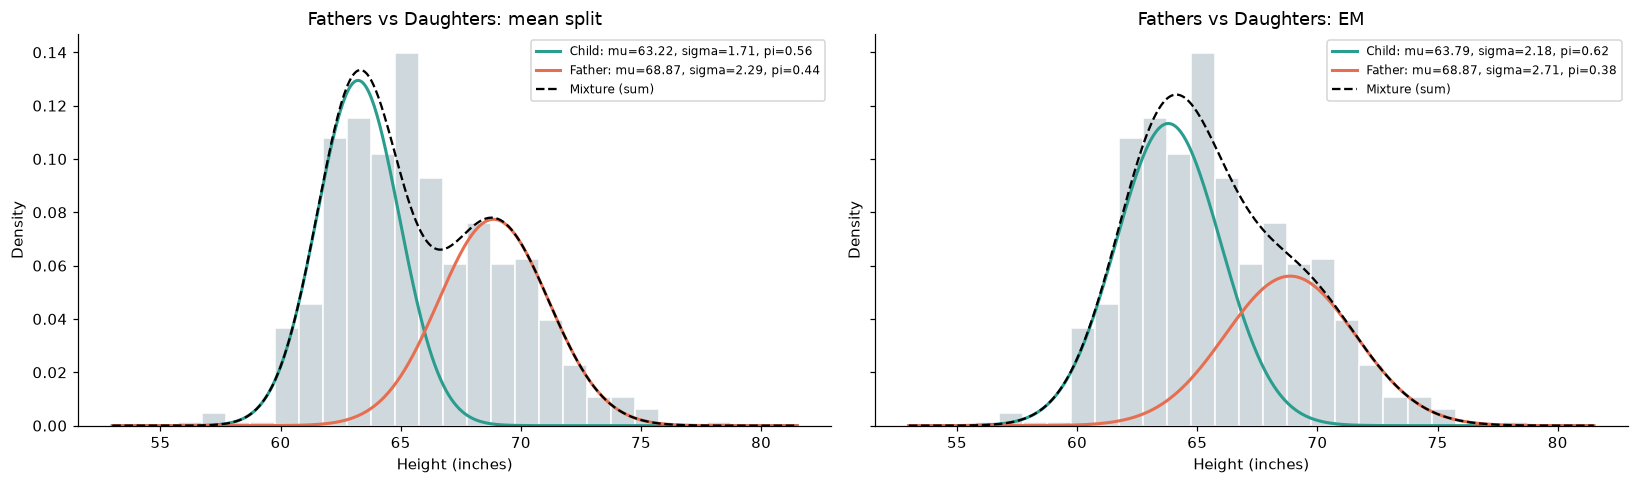

In [13]:
daughters = df.loc[df["gender"] == "female", "childHeight"].to_numpy(float)
fathers = heights[labels == 1]
x2 = np.concatenate([daughters, fathers])
y2 = np.concatenate([np.zeros(daughters.size, int), np.ones(fathers.size, int)])

split2 = mean_split_estimate(x2)
em2 = fit_em(x2, init=split2)[-1].params

def summarise(name, mu, var, pi, acc):
    return {"Method": name, "mu1 (Daughter)": mu[0], "mu2 (Father)": mu[1],
            "sigma1^2": var[0], "sigma2^2": var[1], "pi1": pi[0], "Accuracy": acc}

comparison = pd.DataFrame([
    summarise("TRUE (labels)", [daughters.mean(), fathers.mean()], [daughters.var(), fathers.var()],
              [daughters.size / x2.size], 1.0),
    summarise("Mean split", split2.mu, split2.var, split2.pi, ((x2 > x2.mean()).astype(int) == y2).mean()),
    summarise("EM", em2.mu, em2.var, em2.pi, score_against_labels(e_step(x2, em2)[0], y2)),
]).set_index("Method")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
plot_mixture(axes[0], x2, split2, "Fathers vs Daughters: mean split")
plot_mixture(axes[1], x2, em2, "Fathers vs Daughters: EM")
fig.tight_layout(); fig.savefig(FIG_DIR / "06_controlled_experiment.png", bbox_inches="tight"); plt.show()

With two genuinely different populations, EM beats the mean split on four of the five parameters and ties on the fifth:
the daughters' mean moves from 63.22 to 63.79 (true 64.10), the daughters' variance is no longer shrunk to about half its real size (2.94, then 4.75, true 5.54),
the fathers' variance error drops from 1.74 to 0.38, the mixing weight moves from 0.56 toward the true 0.69, and the fathers' mean is a tie (68.87 for both, true 69.32,
because daughters taller than 66.5 inches still pull it down). Accuracy rises from 81% to 86%.

## 8. Conclusion

**Should you split at the global mean and average each pile? No**, except as a starting point.
It ignores overlap, biases the means outward and the variances downward, forces the mixing weights,
and gives no probabilities. EM keeps the overlap, assigns each height a probability for each group,
and climbs the log likelihood until it stops improving (from −3071.1 at the mean split to −3047.0 at convergence here).

**Second lesson:** an unsupervised model finds the structure that is really in the data.
In Galton's data that structure is sex, so labelling the components "Child" and "Father" must be checked, and here it does not hold.